# Frente de ML – variante: segurar a posição até a mudança de sinal

**Pergunta:** operando a cada minuto, o custo (5 pts) é ~8× maior que o ganho do modelo (~0,6 pt). Segurar a posição até a previsão mudar de sinal reduz o número de operações o suficiente para dar lucro?

Regra registrada **antes** de rodar em `resultados/ml/hipotese_segurar_posicao.json`:

| Item | Regra |
|---|---|
| Modelo | Oficial da frente: `rf_d4_f2`, 1 min, janela de 12 meses, re-treino trimestral |
| Entrada | Compra se previsão > +limiar; vende se previsão < −limiar |
| Manutenção | Mantém a posição até a previsão passar o limiar **do lado oposto** (vira a mão) |
| Fim do dia | Zera no último fechamento do pregão |
| Custo | 5 pts por operação completa (2,5 na entrada + 2,5 na saída); sensibilidade 0 e 10 |
| Limiar | Quantis 0/50/75/90% de \|previsão\| na validação 2024; escolhido na validação (esperança > 0 com t ≥ 2) |

Períodos: validação 2024 (escolha do limiar) → teste oficial 01/2025–03/2026 → período nunca visto 04–09/2026.

In [1]:
import os, sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
import tt1_comum as t

SAIDA = f"{PASTA}/resultados/ml"
CFG = json.load(open(f"{SAIDA}/config_final.json", encoding="utf-8"))
FEATS = t.features()["COMPLETO"]
CANDLE, JANELA = CFG["candle"], CFG["janela_meses"]
NOVO = ("2026-04-01", "2026-09-26")
QUANTIS = [0.0, 0.5, 0.75, 0.9]
print(CFG["modelo"], CANDLE, JANELA)

class FolhaProporcional:
    # mesmo modelo de frente_ml.ipynb: min_samples_leaf = max(10, folha_frac × nº de linhas do treino)
    def __init__(self, estimador, folha_frac=0.01, folha_min=10):
        self.estimador, self.folha_frac, self.folha_min = estimador, folha_frac, folha_min
    def fit(self, X, y):
        self.min_leaf_ = max(self.folha_min, int(self.folha_frac * len(X)))
        self.m = clone(self.estimador).set_params(min_samples_leaf=self.min_leaf_).fit(X, y)
        return self
    def predict(self, X):
        return self.m.predict(X)

assert CFG["modelo"] == "rf_d4_f2"
FABRICA = lambda: FolhaProporcional(RandomForestRegressor(n_estimators=CFG["n_arvores"], max_depth=4, max_features=0.5,
                                                          n_jobs=-1, random_state=42), folha_frac=0.02)

rf_d4_f2 1min 12


## Previsões do modelo oficial nos três períodos

- Validação 2024 e período novo: geradas aqui (as previsões de validação da variante oficial não tinham sido salvas).
- Teste oficial: reaproveita `WIN_1min_12m_rf_teste.csv`, gerado em `frente_ml.ipynb`.
- Período novo: base só com WIN (o RF não usa o WDO; o WIN é passado no lugar do WDO e as colunas `*_wdo` não entram nas features).

In [2]:
win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
df_comum, _ = t.montar_base(win, wdo, CANDLE)
df_win, _ = t.montar_base(win, win, CANDLE)

PREV = {
    "validacao_2024": t.walk_forward(df_comum, FEATS, FABRICA, *t.VALIDACAO, janela_meses=JANELA),
    "teste_2025_03-2026": pd.read_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_rf_teste.csv", index_col=0, parse_dates=True),
    "novo_04-09-2026": t.walk_forward(df_win, FEATS, FABRICA, *NOVO, janela_meses=JANELA),
}
PREV["validacao_2024"].to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_{CFG['modelo']}_val.csv")
PREV["novo_04-09-2026"].to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_{CFG['modelo']}_abr_set_2026.csv")
LIMIARES = {q: t.limiar_por_quantil(PREV["validacao_2024"], q) for q in QUANTIS}
for k, p in PREV.items():
    print(f"{k}: {len(p):,} candles | Theil U {t.metricas(p)['TheilU']:.4f}")
print({f"{q:.0%}": round(l, 6) for q, l in LIMIARES.items()})

validacao_2024: 141,216 candles | Theil U 1.0000
teste_2025_03-2026: 174,579 candles | Theil U 0.9999
novo_04-09-2026: 68,945 candles | Theil U 0.9997
{'0%': 0.0, '50%': 0.000236, '75%': 0.000414, '90%': 0.00079}


## Simulação: segurar a posição

In [3]:
def posicoes(prev, limiar):
    # posição decidida no fechamento de cada candle; zera a cada novo pregão
    yp, dia = prev.y_pred.values, prev.index.date
    pos, p = np.zeros(len(prev)), 0
    for i in range(len(prev)):
        if i == 0 or dia[i] != dia[i - 1]:
            p = 0
        if yp[i] > limiar:
            p = 1
        elif yp[i] < -limiar:
            p = -1
        pos[i] = p
    return pos

def operacoes_segurando(prev, limiar, custo_pts):
    # agrupa os minutos em operações completas (da entrada até a saída/virada/fim do dia)
    pos = posicoes(prev, limiar)
    dia = pd.Series(prev.index.date, index=prev.index)
    mov = prev.close_prox.values - prev.close.values
    nova = (pos != np.roll(pos, 1)) | (dia != dia.shift()).values
    nova[0] = True
    op_id = np.cumsum(nova)
    d = pd.DataFrame({"op": op_id, "lado": pos, "pts": pos * mov, "inicio": prev.index}, index=prev.index)
    d = d[d.lado != 0]
    ops = d.groupby("op").agg(lado=("lado", "first"), bruto=("pts", "sum"), minutos=("pts", "size"), inicio=("inicio", "first"))
    ops["pontos"] = ops.bruto - custo_pts
    return ops

def resumo(ops, n_candles):
    x = ops.pontos
    ep = x.std() / np.sqrt(len(x)) if len(x) > 1 else np.nan
    g, p = x[x > 0], x[x < 0]
    return dict(n_ops=len(x), ops_por_dia=len(x) / max(1, ops.inicio.dt.date.nunique()),
                minutos_medios=ops.minutos.mean(), pct_tempo_posicionado=ops.minutos.sum() / n_candles,
                taxa_acerto=(x > 0).mean(), payoff=g.mean() / -p.mean() if len(g) and len(p) else np.nan,
                esperanca_pts=x.mean(), ep_pts=ep, t_stat=x.mean() / ep,
                fator_lucro=g.sum() / -p.sum() if len(p) else np.inf, resultado_R=x.sum() * t.PONTO_WIN)

def aleatorio(ops, custo_pts, seed=42):
    # mesmas operações e durações, direção sorteada
    rng = np.random.default_rng(seed)
    return ops.assign(pontos=ops.bruto * rng.choice([-1, 1], size=len(ops)) - custo_pts)

linhas = []
for periodo, prev in PREV.items():
    for q, lim in LIMIARES.items():
        for custo in t.CUSTOS_PTS:
            ops = operacoes_segurando(prev, lim, custo)
            linhas.append(dict(periodo=periodo, regra="segurar", limiar_q=q, custo_pts=custo, **resumo(ops, len(prev))))
            linhas.append(dict(periodo=periodo, regra="segurar_aleatorio", limiar_q=q, custo_pts=custo,
                               **resumo(aleatorio(ops, custo), len(prev))))
        for custo in t.CUSTOS_PTS:   # referência: regra oficial, uma operação por minuto
            o = t.simular(prev, lim, None, None, custo)
            x = o[o.lado != 0].pontos
            g, p = x[x > 0], x[x < 0]
            ep = x.std() / np.sqrt(len(x))
            linhas.append(dict(periodo=periodo, regra="por_minuto", limiar_q=q, custo_pts=custo, n_ops=len(x),
                               minutos_medios=1.0, taxa_acerto=(x > 0).mean(), payoff=g.mean() / -p.mean(),
                               esperanca_pts=x.mean(), ep_pts=ep, t_stat=x.mean() / ep,
                               fator_lucro=g.sum() / -p.sum(), resultado_R=x.sum() * t.PONTO_WIN))
res = pd.DataFrame(linhas)
res.to_csv(f"{SAIDA}/segurar_posicao.csv", index=False)

## Escolha do limiar na validação 2024 (custo 5 pts)

In [4]:
v = res[(res.periodo == "validacao_2024") & (res.regra == "segurar") & (res.custo_pts == 5)]
display(v[["limiar_q", "n_ops", "ops_por_dia", "minutos_medios", "taxa_acerto", "payoff", "esperanca_pts", "ep_pts",
           "t_stat", "fator_lucro", "resultado_R"]].round(3))
ok = v[(v.esperanca_pts > 0) & (v.t_stat >= 2)]
Q_ESCOLHIDO = float(ok.sort_values("esperanca_pts", ascending=False).iloc[0].limiar_q) if len(ok) else None
print("Limiar escolhido:", f"{Q_ESCOLHIDO:.0%}" if Q_ESCOLHIDO is not None else
      "nenhum com t ≥ 2 → sem evidência; os períodos de teste ficam só como sensibilidade")

,limiar_q,n_ops,ops_por_dia,minutos_medios,taxa_acerto,payoff,esperanca_pts,ep_pts,t_stat,fator_lucro,resultado_R
2,0.00,52283,208.299,2.701,0.498,0.739,-4.218,0.303,-13.932,0.822,-44108.0
11,0.50,21316,84.924,6.621,0.544,0.710,-3.518,0.731,-4.812,0.906,-14999.0
20,0.75,13626,54.287,10.353,0.562,0.699,-2.539,1.130,-2.247,0.945,-6919.0
29,0.90,6364,25.355,22.130,0.576,0.683,-2.502,2.437,-1.027,0.962,-3185.0


Limiar escolhido: nenhum com t ≥ 2 → sem evidência; os períodos de teste ficam só como sensibilidade


## Resultado nos períodos de teste (custo 5 pts)

In [5]:
cols = ["periodo", "limiar_q", "regra", "n_ops", "ops_por_dia", "minutos_medios", "taxa_acerto", "payoff",
        "esperanca_pts", "t_stat", "fator_lucro", "resultado_R"]
tab = res[(res.custo_pts == 5)].sort_values(["periodo", "limiar_q", "regra"])
display(tab[cols].round(3))

,periodo,limiar_q,regra,n_ops,ops_por_dia,minutos_medios,taxa_acerto,payoff,esperanca_pts,t_stat,fator_lucro,resultado_R
79,novo_04-09-2026,0.00,por_minuto,68945,NaN,1.000,0.438,0.992,-4.342,-14.581,0.843,-59865.0
74,novo_04-09-2026,0.00,segurar,24251,197.163,2.843,0.500,0.873,-3.128,-3.695,0.929,-15171.0
75,novo_04-09-2026,0.00,segurar_aleatorio,24251,197.163,2.843,0.454,1.011,-5.056,-5.971,0.888,-24521.0
88,novo_04-09-2026,0.50,por_minuto,32143,NaN,1.000,0.468,0.967,-3.271,-5.972,0.907,-21026.0
83,novo_04-09-2026,0.50,segurar,13617,110.707,5.063,0.533,0.822,-1.235,-0.821,0.980,-3364.0
84,novo_04-09-2026,0.50,segurar_aleatorio,13617,110.707,5.063,0.470,1.009,-4.777,-3.175,0.924,-13010.0
97,novo_04-09-2026,0.75,por_minuto,22725,NaN,1.000,0.477,0.961,-2.888,-4.072,0.925,-13124.0
92,novo_04-09-2026,0.75,segurar,10493,85.309,6.570,0.554,0.784,0.376,0.192,1.005,790.0
93,novo_04-09-2026,0.75,segurar_aleatorio,10493,85.309,6.570,0.472,0.962,-8.563,-4.376,0.885,-17970.0
106,novo_04-09-2026,0.90,por_minuto,14022,NaN,1.000,0.486,0.961,-1.957,-1.976,0.954,-5489.0


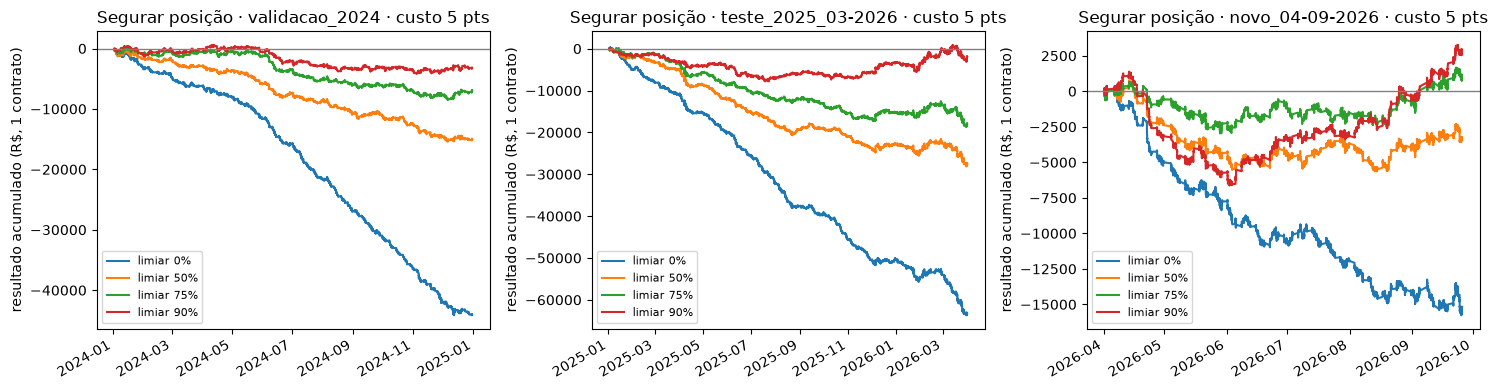

Ganho por operação ANTES do custo (pts):
regra                        por_minuto  segurar
periodo            limiar_q                     
novo_04-09-2026    0.00            0.66     1.87
                   0.50            1.73     3.76
                   0.75            2.11     5.38
                   0.90            3.04     6.93
teste_2025_03-2026 0.00            0.59     1.23
                   0.50            0.94     2.13
                   0.75            1.07     2.01
                   0.90            1.99     4.27
validacao_2024     0.00            0.29     0.78
                   0.50            0.34     1.48
                   0.75            0.61     2.46
                   0.90            1.45     2.50


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, periodo in zip(axes, PREV):
    for q in QUANTIS:
        ops = operacoes_segurando(PREV[periodo], LIMIARES[q], 5)
        (ops.set_index("inicio").pontos.cumsum() * t.PONTO_WIN).plot(ax=ax, label=f"limiar {q:.0%}")
    ax.axhline(0, color="gray", lw=1)
    ax.set_title(f"Segurar posição · {periodo} · custo 5 pts"); ax.set_xlabel("")
    ax.set_ylabel("resultado acumulado (R$, 1 contrato)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/segurar_posicao_curvas.png", dpi=150); plt.show()

# ganho bruto por operação × custo: quanto o modelo ganha antes do custo em cada regra
bruto = res[(res.custo_pts == 0) & (res.regra.isin(["segurar", "por_minuto"]))].pivot_table(
    index=["periodo", "limiar_q"], columns="regra", values="esperanca_pts")
print("Ganho por operação ANTES do custo (pts):")
print(bruto.round(2))